# Lead-lag: does Kalshi move before our play timestamps?

The 799-game comparison (`kalshi_comparison.ipynb`) showed our model predicts winners no
better than Kalshi. So the market maker's edge, if any, is timing. When a basket is scored,
does the Kalshi price move **before** the NBA feed's timestamp for that play (then our
quotes would be stale and get picked off) or **after** it (then we can keep up)?

Background and method: `LeadLag_Plan.md`. All data comes from `src/lead_lag.py`, which saves
it to `data/processed/lead_lag_events.parquet`; this notebook makes no API calls.

## Setup

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

%matplotlib inline
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd

import lead_lag as ll
import lead_lag_plots as llp  # every chart below

events = ll.load_events()
COLUMNS = ["games", "plays", "model jump (c)", "market move (c)", "share by 0", "share by 0 lo", "share by 0 hi", "half done at (s)", "half lo", "half hi"]
local = events["time"].dt.tz_convert("America/New_York")
print(f"{events['game_id'].nunique()} games, {len(events):,} scoring plays, "
      f"{local.min():%Y-%m-%d} to {local.max():%Y-%m-%d} (US Eastern)")

150 games, 8,105 scoring plays, 2025-04-19 to 2026-01-31 (US Eastern)


**What is in the data.** Games are the first 150 of the same seeded random order as the
batch comparison. For each game we have every Kalshi trade (timestamped to the microsecond,
a median of well under a second apart) and every score change from the NBA live feed.

A scoring play is used only if:

- **it is isolated**: no other score change within 20 s either side, so the window around
  it holds one event (this drops free-throw pairs and quick answers),
- **its timestamp is in order**: plays logged behind an earlier play are dropped,
- **the price can move**: Kalshi was between 3 and 97 cents 20 s before it.

For each play we take the last trade price at every second from -20 s to +20 s around the
feed's timestamp. Moves are signed so the scoring team's direction is up, averaged within
each game, then across games (each game counted once; ±95% intervals by resampling games).

## 1. When does the market move?

Left: Kalshi's average price change around a scoring play. Right: the same move as a share
of the full move by +20 s. The red dotted line marks when half the move is done; left of
the grey line means the market moves **before** our timestamp.

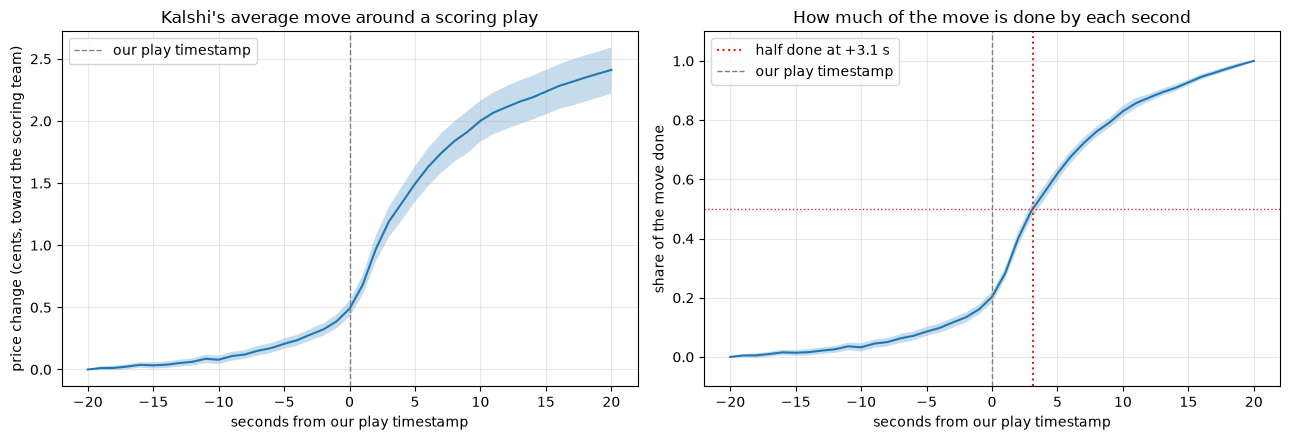

,games,plays,model jump (c),market move (c),share by 0,share by 0 lo,share by 0 hi,half done at (s),half lo,half hi
group,,,,,,,,,,
all,150,8105,4.55,2.411,0.203,0.183,0.22,3.105,2.827,3.488


In [2]:
llp.response(events)
plt.show()
ll.summary(events)[COLUMNS].round(3)

## 2. When does trading pick up?

A second view that does not depend on prices: trades per second around a scoring play,
relative to the rate 20 s before. If traders react before our timestamp, the burst starts
before 0.

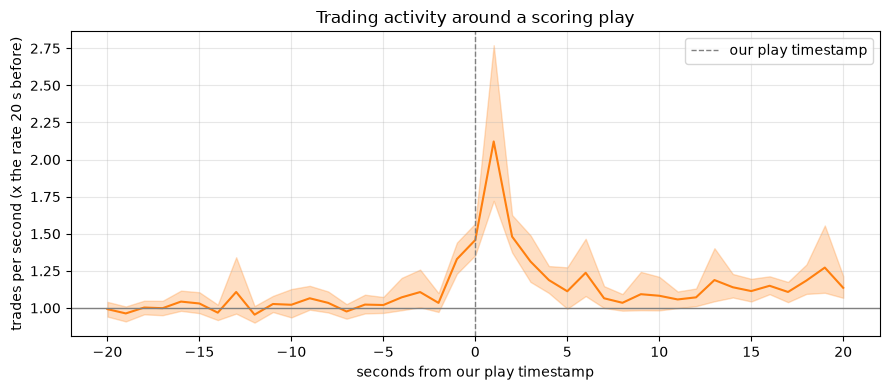

In [3]:
llp.activity(events)
plt.show()

## 3. Does it depend on the situation?

The same share curve by quarter and by game state (close game: Kalshi between 30% and 70%
before the play). Late, close games matter most: that is where a basket moves the price
the most.

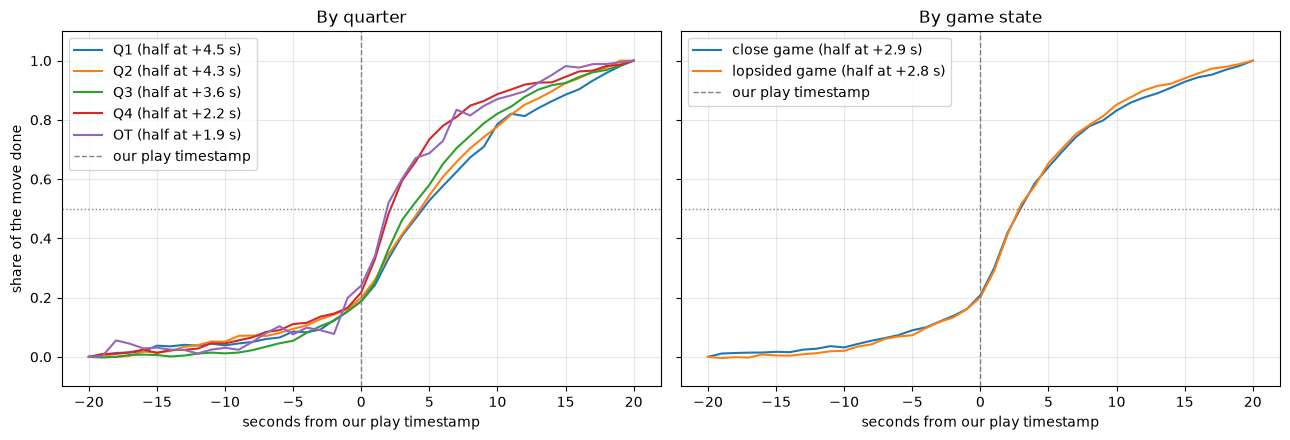

games  plays  model jump (c)  market move (c)  \
           group                                                          
quarter    1                150   2092           3.205            1.533   
           2                149   2322           3.418            1.870   
           3                143   2065           4.171            2.432   
           4                127   1528           8.066            4.026   
           5                 13     98          13.247            7.852   
game_state close game       126   3720           5.550            3.462   
           lopsided game    150   4385           3.702            2.186   

                          share by 0  share by 0 lo  share by 0 hi  \
           group                                                     
quarter    1                   0.188          0.158          0.221   
           2                   0.200          0.165          0.234   
           3                   0.188          0.158          0.218   
           4                   0.218          0.180          0.251   
           5                   0.241          0.118          0.349   
game_state close game          0.208          0.179          0.237   
           lopsided game       0.201          0.169          0.231   

                          half done at (s)  half lo  half hi  
           group                                              
quarter    1                         4.536    3.945    5.175  
           2                         4.344    3.835    4.842  
           3                         3.619    3.126    4.136  
           4                         2.155    1.834    2.538  
           5                         1.891    1.262    3.763  
game_state close game                2.942    2.596    3.293  
           lopsided game             2.845    2.538    3.260

In [4]:
llp.by_group(events)
plt.show()
pd.concat({by: ll.summary(events, by)[COLUMNS] for by in ["quarter", "game_state"]}).round(3)

## 4. Example plays

Raw Kalshi trades around six random scoring plays (price as P(home wins)), to show what is
being averaged: trades bounce between bid and ask, and the step comes a few seconds around
the timestamp.

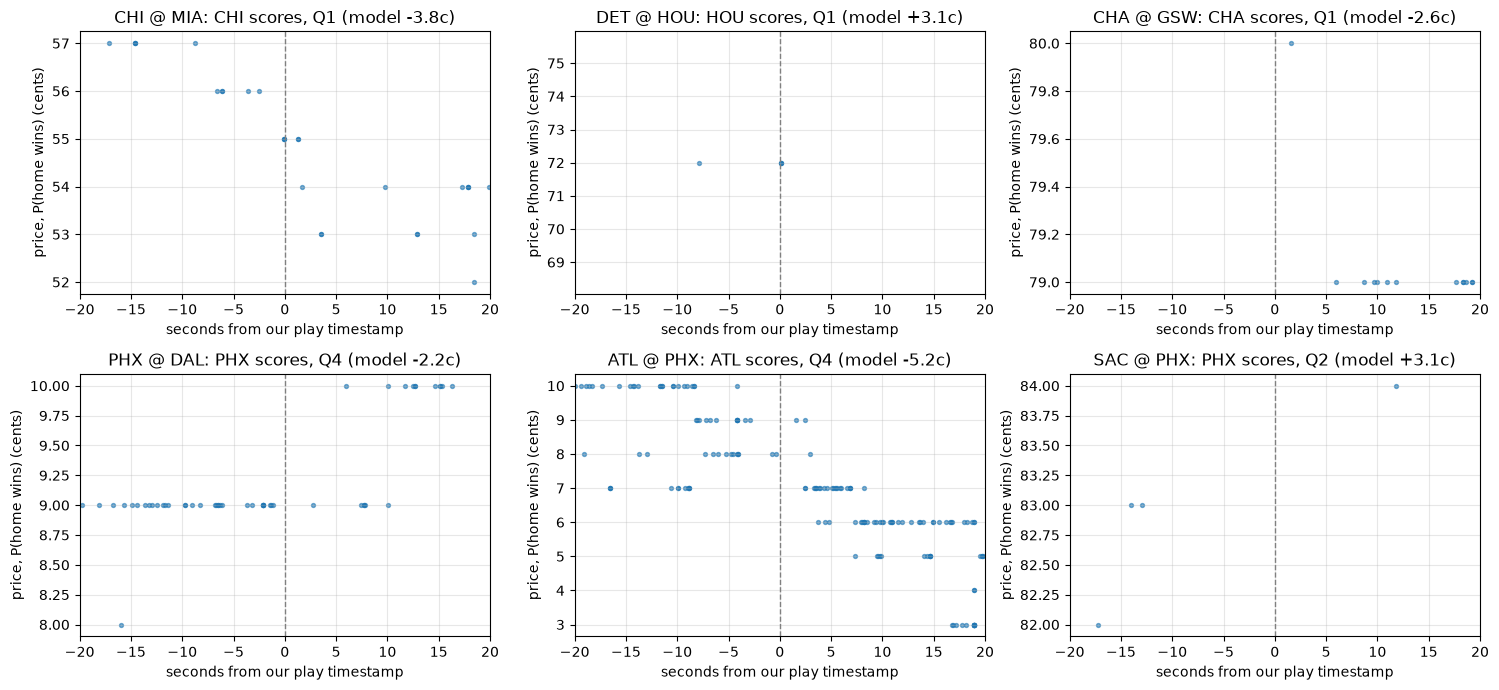

In [5]:
llp.examples(events)
plt.show()

## Conclusions

**1. Kalshi reacts after our timestamp, not before.** By the feed's timestamp the market has
moved 0.5 cents of the 2.4 it moves by +20 s (20%, ±2%). Half the move is done at +3.1 s
(2.8 to 3.5 s). Trading tells the same story without using prices: it is flat until about
1 s before the timestamp and peaks 1 s after it, at 2.1 times the normal rate. So the
feed's timestamps mark the play closely, and Kalshi traders take 1-3 s to react.

**2. The small move before the timestamp looks like anticipation, not a faster feed.** The
price starts drifting about 10 s early, but trading activity stays flat until the last
second. That fits traders pricing a likely basket (a fast break, free throws coming) more
than anyone seeing the basket before it is logged.

**3. Late in games the market is faster and moves more.** Half the move is done at +2.2 s
in Q4 (a 4.0-cent move) against +4.5 s in Q1 (1.5 cents). Close and lopsided games barely
differ (+2.9 s and +2.8 s). Stale quotes are most dangerous late in the game.

**4. Within 20 s the market moves about half as much as the model.** The model jumps 4.6
cents per scoring play, the market 2.4. Part of the gap is that the market is still
drifting at +20 s. Part is likely that the market had partly priced the basket in
beforehand (free throws especially), while the model treats every point as a surprise.
This matches the batch comparison, where the model was more extreme than the market.

### What this means for the quoting rule

- **Speed decides it.** Most of the reaction happens in the first 3 s after a play, so our
  quotes need each play within about 1-2 s of its timestamp to keep up.
- **Pull or widen quotes for a few seconds after every score**, until the price settles.
  The trading burst at +1 s is when stale quotes get picked off, and it matters most in Q4.
- **Don't move quotes by the model's full jump.** The market moves about half of it.

### Caveats and next checks

- **Feed delay is the deciding number.** This compares the market with when the play
  happened, not with when our feed would deliver it. If the live feed arrives more than
  about 2 s late, most of the move happens before we see it. Measure it by logging the
  feed's arrival time for each play during a live game; games are on now.
- **The share numbers depend on the 20 s window**, because the market is still drifting at
  +20 s. The cents moved by each second and the trading burst don't depend on it.
- **One market per game.** Only the home team's market is used; the other team's market
  trades too.